# Previsão de recompra em um e-commerce brasileiro (Olist)

**Autora:** Thaís Miranda Lopes

Esta é a Parte 3 do estudo. Na Parte 1 vi que quase ninguém volta a comprar. Na Parte 2 separei os clientes em segmentos. Agora a pergunta é:

**Dá para prever, logo depois da primeira compra, quem vai voltar?**

Se desse, o CRM poderia investir mais em quem tem mais chance de recomprar.

**Resumo do resultado:** o modelo ficou fraco, e isso é uma resposta útil. Os dados da primeira compra dizem pouco sobre quem volta. O notebook mostra como cheguei nessa conclusão e o que eu faria no lugar.

**Ferramentas:** Python, Pandas e Scikit-learn.

## 1. Preparação

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PASTA_DADOS = "../dados/"
PASTA_IMAGENS = "../imagens/"
CINZA = "#BDBDBD"
PRETO = "#212121"

pedidos = pd.read_csv(
    PASTA_DADOS + "olist_orders_dataset.csv",
    parse_dates=["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"],
)
itens = pd.read_csv(PASTA_DADOS + "olist_order_items_dataset.csv")
clientes = pd.read_csv(PASTA_DADOS + "olist_customers_dataset.csv")
avaliacoes = pd.read_csv(PASTA_DADOS + "olist_order_reviews_dataset.csv", parse_dates=["review_answer_timestamp"])
produtos = pd.read_csv(PASTA_DADOS + "olist_products_dataset.csv")
pagamentos = pd.read_csv(PASTA_DADOS + "olist_order_payments_dataset.csv")

# Mesma base das partes anteriores: pedidos entregues, com o cliente real.
entregues = pedidos[pedidos["order_status"] == "delivered"].merge(clientes, on="customer_id")
entregues = entregues.sort_values("order_purchase_timestamp")

print("Pedidos entregues:", len(entregues))
print("Clientes únicos:", entregues["customer_unique_id"].nunique())

Pedidos entregues: 96478
Clientes únicos: 93358


## 2. O que é "recompra"?

Antes de treinar qualquer modelo, preciso definir com cuidado o que quero prever. Para cada pedido, calculo quantos dias se passaram desde a primeira compra daquele cliente.

In [2]:
# Primeira compra de cada cliente (a base já está ordenada por data).
primeira_compra = entregues.drop_duplicates("customer_unique_id", keep="first").copy()

# Dias entre cada pedido e a primeira compra do mesmo cliente.
data_primeira = primeira_compra.set_index("customer_unique_id")["order_purchase_timestamp"]
entregues["dias_desde_primeira"] = (
    entregues["order_purchase_timestamp"] - entregues["customer_unique_id"].map(data_primeira)
).dt.total_seconds() / 86400

pedidos_por_cliente = entregues.groupby("customer_unique_id").size()

clientes_com_mais_de_um = (pedidos_por_cliente > 1).sum()
clientes_dia_seguinte = entregues[entregues["dias_desde_primeira"] >= 1]["customer_unique_id"].nunique()
total = len(primeira_compra)

print("Clientes com mais de um pedido:", clientes_com_mais_de_um, f"({clientes_com_mais_de_um / total * 100:.1f}%)")
print("Clientes que voltaram pelo menos 1 dia depois:", clientes_dia_seguinte, f"({clientes_dia_seguinte / total * 100:.1f}%)")
print("Clientes com novos pedidos só nas primeiras 24 horas:", clientes_com_mais_de_um - clientes_dia_seguinte)

Clientes com mais de um pedido: 2801 (3.0%)
Clientes que voltaram pelo menos 1 dia depois: 1993 (2.1%)
Clientes com novos pedidos só nas primeiras 24 horas: 808


**Achado importante.** Dos 2.801 clientes com mais de um pedido, 808 só fizeram novos pedidos nas primeiras 24 horas. Isso é um carrinho dividido em dois, não um cliente que voltou.

A recompra de verdade, em outro dia, é de **2,1%**, não 3,0%. Este número corrige a leitura da Parte 1.

**Definição do alvo.** Para o modelo, "recomprou" significa: fez um novo pedido entre 1 e 180 dias depois da primeira compra.

In [3]:
JANELA_DIAS = 180

na_janela = entregues[(entregues["dias_desde_primeira"] >= 1) & (entregues["dias_desde_primeira"] <= JANELA_DIAS)]
clientes_que_recompraram = na_janela["customer_unique_id"].unique()

primeira_compra["recomprou"] = primeira_compra["customer_unique_id"].isin(clientes_que_recompraram).astype(int)

# Quantos pedidos o cliente fez nas primeiras 24 horas (o carrinho dividido).
pedidos_primeiro_dia = entregues[entregues["dias_desde_primeira"] < 1].groupby("customer_unique_id").size()
primeira_compra["pedidos_no_primeiro_dia"] = primeira_compra["customer_unique_id"].map(pedidos_primeiro_dia)

**Decisão: quem entra na base do modelo.** Só clientes com a primeira compra entre janeiro de 2017 e fevereiro de 2018.

O motivo: a base termina em agosto de 2018. Quem comprou pela primeira vez em julho de 2018 não teve 180 dias para voltar. Se eu deixasse essas pessoas, o modelo aprenderia que "cliente recente não recompra", o que é falso. Elas só não tiveram tempo.

In [4]:
base = primeira_compra[
    (primeira_compra["order_purchase_timestamp"] >= "2017-01-01")
    & (primeira_compra["order_purchase_timestamp"] < "2018-03-01")
].copy()

taxa = base["recomprou"].mean() * 100
print("Clientes na base do modelo:", len(base))
print("Recompraram em até 180 dias:", base["recomprou"].sum(), f"({taxa:.2f}%)")

Clientes na base do modelo: 55261
Recompraram em até 180 dias: 1080 (1.95%)


Só 2 em cada 100 clientes recompram. A base é muito **desbalanceada**: um resultado é raro e o outro é quase tudo. Isso muda a forma de avaliar o modelo, como mostro na seção 5.

## 3. As pistas que o modelo vai usar

O modelo só pode usar o que já se sabe sobre a **primeira compra**. Montei 11 pistas (em inglês, *features*).

| Pista | O que é |
|---|---|
| `valor`, `frete`, `itens` | Quanto gastou, quanto pagou de frete e quantos itens levou |
| `parcelas`, `forma_pagamento` | Em quantas vezes pagou e como |
| `categoria` | Categoria do item mais caro do pedido |
| `estado` | Estado do cliente |
| `dias_entrega`, `atrasou` | Quanto tempo a entrega levou e se passou do prazo |
| `nota` | Nota que o cliente deu ao pedido |
| `pedidos_no_primeiro_dia` | Quantos pedidos fez nas primeiras 24 horas |

In [5]:
# Valor, frete e quantidade de itens de cada pedido.
itens_com_categoria = itens.merge(produtos[["product_id", "product_category_name"]], on="product_id", how="left")

resumo_pedido = itens_com_categoria.groupby("order_id").agg(
    valor=("price", "sum"),
    frete=("freight_value", "sum"),
    itens=("order_item_id", "count"),
).reset_index()

# Categoria do item mais caro de cada pedido.
categoria_pedido = (
    itens_com_categoria.sort_values("price", ascending=False)
    .drop_duplicates("order_id")[["order_id", "product_category_name"]]
)

# Parcelas e forma de pagamento principal de cada pedido.
parcelas_pedido = pagamentos.groupby("order_id").agg(parcelas=("payment_installments", "max")).reset_index()
forma_pedido = (
    pagamentos.sort_values("payment_value", ascending=False)
    .drop_duplicates("order_id")[["order_id", "payment_type"]]
    .rename(columns={"payment_type": "forma_pagamento"})
)

# Avaliação mais recente de cada pedido.
nota_pedido = (
    avaliacoes.sort_values("review_answer_timestamp")
    .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]]
    .rename(columns={"review_score": "nota"})
)

linhas_antes = len(base)
for tabela in [resumo_pedido, categoria_pedido, parcelas_pedido, forma_pedido, nota_pedido]:
    base = base.merge(tabela, on="order_id", how="left")

print("Linhas antes das junções:", linhas_antes)
print("Linhas depois das junções:", len(base))

Linhas antes das junções: 55261
Linhas depois das junções: 55261


In [6]:
base["dias_entrega"] = (base["order_delivered_customer_date"] - base["order_purchase_timestamp"]).dt.days
base["atrasou"] = (
    base["order_delivered_customer_date"].dt.normalize() > base["order_estimated_delivery_date"]
).astype(int)

# Categorias e estados pequenos viram "outras" e "outros".
# Sem isso o modelo tentaria aprender com grupos de poucos clientes.
maiores_categorias = base["product_category_name"].value_counts().head(15).index
base["categoria"] = base["product_category_name"].where(base["product_category_name"].isin(maiores_categorias), "outras")
base["categoria"] = base["categoria"].fillna("outras")

maiores_estados = base["customer_state"].value_counts().head(8).index
base["estado"] = base["customer_state"].where(base["customer_state"].isin(maiores_estados), "outros")

pistas_numericas = ["valor", "frete", "itens", "parcelas", "nota", "dias_entrega", "atrasou", "pedidos_no_primeiro_dia"]
pistas_de_texto = ["categoria", "estado", "forma_pagamento"]

print("Campos vazios nas pistas:")
vazios = base[pistas_numericas + pistas_de_texto].isna().sum()
print(vazios[vazios > 0].to_string())

Campos vazios nas pistas:
nota            410
dias_entrega      2


Sobraram poucos vazios: clientes que não avaliaram o pedido e dois pedidos sem data de entrega. O modelo vai preencher esses campos com a mediana (seção 4).

### Um olhar rápido antes de modelar

Vale conferir se alguma pista sozinha já separa quem recompra.

In [7]:
for pista in ["atrasou", "pedidos_no_primeiro_dia", "forma_pagamento"]:
    resumo = base.groupby(pista)["recomprou"].agg(["mean", "count"])
    resumo.columns = ["taxa_recompra_%", "clientes"]
    resumo["taxa_recompra_%"] = (resumo["taxa_recompra_%"] * 100).round(2)
    print(resumo[resumo["clientes"] >= 500].sort_values("taxa_recompra_%", ascending=False).to_string())
    print()

         taxa_recompra_%  clientes
atrasou                           
0                   1.98     51588
1                   1.61      3673

                         taxa_recompra_%  clientes
pedidos_no_primeiro_dia                           
2                                   4.62       650
1                                   1.91     54585

                 taxa_recompra_%  clientes
forma_pagamento                           
voucher                     2.60      1808
boleto                      1.97     11553
debit_card                  1.93       571
credit_card                 1.92     41329



**Leitura:** nenhuma pista sozinha separa bem quem volta.

- Quem recebeu com atraso recompra um pouco menos: 1,61% contra 1,98%.
- Quem pagou com voucher recompra um pouco mais: 2,60%.
- Quem fez 2 pedidos no primeiro dia recompra bem mais (4,62% contra 1,91%), mas são só 650 clientes.

As diferenças existem, mas são pequenas. Já é um sinal de que o modelo vai ter dificuldade.

## 4. Treino e teste

**Por que separar.** Avaliar o modelo nos mesmos clientes que ele usou para aprender é como dar a prova com as respostas. Separo 25% dos clientes, que o modelo nunca vê, para testar.

O `stratify` garante a mesma proporção de recompra nas duas partes.

In [8]:
X = base[pistas_numericas + pistas_de_texto]
y = base["recomprou"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42
)

print("Treino:", len(X_treino), "clientes,", y_treino.sum(), "recompraram")
print("Teste: ", len(X_teste), "clientes,", y_teste.sum(), "recompraram")

Treino: 41445 clientes, 810 recompraram
Teste:  13816 clientes, 270 recompraram


In [9]:
# O modelo só entende números. Esta etapa prepara as pistas:
# - números: preenche os vazios com a mediana e coloca tudo na mesma escala
# - textos: transforma cada opção em uma coluna de 0 ou 1
preparacao = ColumnTransformer([
    ("numeros", Pipeline([
        ("preencher", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
    ]), pistas_numericas),
    ("textos", OneHotEncoder(handle_unknown="ignore"), pistas_de_texto),
])

# Três modelos, do mais simples ao mais complexo.
modelos = {
    "Chute (sempre diz que não recompra)": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": LogisticRegression(class_weight="balanced", max_iter=1000),
    "Floresta aleatória": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=20, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

treinados = {}
for nome, modelo in modelos.items():
    esteira = Pipeline([("preparacao", preparacao), ("modelo", modelo)])
    esteira.fit(X_treino, y_treino)
    treinados[nome] = esteira

print("Modelos treinados:", len(treinados))

Modelos treinados: 3


O `class_weight="balanced"` avisa o modelo que errar um cliente que recompra custa mais caro. Sem isso, com 98% de "não", ele aprenderia a dizer "não" para todo mundo.

O `Pipeline` (esteira) junta a preparação e o modelo. Assim a preparação aprende só com o treino, e o teste continua sendo uma prova justa.

## 5. Avaliação

### A armadilha da acurácia

Acurácia é o percentual de acertos. Parece a medida óbvia, mas veja o que acontece.

In [10]:
resultados = []
for nome, esteira in treinados.items():
    previsao = esteira.predict(X_teste)
    chance = esteira.predict_proba(X_teste)[:, 1]
    resultados.append({
        "modelo": nome,
        "acuracia_%": round(accuracy_score(y_teste, previsao) * 100, 1),
        "auc": round(roc_auc_score(y_teste, chance), 3),
        "recompradores_encontrados": int(((previsao == 1) & (y_teste == 1)).sum()),
    })

pd.DataFrame(resultados)

,modelo,acuracia_%,auc,recompradores_encontrados
0,Chute (sempre diz que não recompra),98.0,0.500,0
1,Regressão logística,57.4,0.585,152
2,Floresta aleatória,85.3,0.567,53


**Leitura:** o "chute" acerta 98,0% das vezes e não encontra nenhum cliente que recompra. Acurácia alta, utilidade zero. Em base desbalanceada, acurácia engana.

Por isso uso o **AUC**. Ele responde: se eu pegar um cliente que recomprou e um que não recomprou, em quantas vezes o modelo dá a maior chance para o que recomprou? O valor 0,5 é sorteio. O valor 1,0 é perfeito.

- Regressão logística: 0,585.
- Floresta aleatória: 0,567.

Os dois ficam pouco acima do sorteio. O modelo mais simples foi o melhor, então sigo com a regressão logística. Ela encontrou 152 dos 270 clientes que recompraram, mas ao custo de muitos alarmes falsos: a acurácia caiu para 57,4%.

In [11]:
# O resultado depende de quais clientes caíram no teste?
# Repito o teste 5 vezes, com divisões diferentes (validação cruzada).
esteira_logistica = Pipeline([
    ("preparacao", preparacao),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

auc_5_vezes = cross_val_score(esteira_logistica, X, y, cv=5, scoring="roc_auc")

print("AUC em cada rodada:", auc_5_vezes.round(3))
print(f"AUC média: {auc_5_vezes.mean():.3f}")

AUC em cada rodada: [0.593 0.548 0.555 0.569 0.597]
AUC média: 0.572


**Leitura:** nas 5 rodadas o AUC ficou entre 0,548 e 0,597, com média de 0,572. O resultado é consistente: o sinal é fraco, mas não é sorte de uma divisão específica.

### O modelo ajuda o CRM na prática?

A pergunta de negócio não é "o modelo acerta?". É: **se eu ordenar os clientes pela chance que o modelo deu, os primeiros da fila recompram mais?**

Divido os clientes do teste em 5 faixas iguais, da menor para a maior chance.

In [12]:
melhor = treinados["Regressão logística"]

teste = pd.DataFrame({
    "chance": melhor.predict_proba(X_teste)[:, 1],
    "recomprou": y_teste.values,
})

nomes_faixas = ["20% menor chance", "faixa 2", "faixa 3", "faixa 4", "20% maior chance"]
teste["faixa"] = pd.qcut(teste["chance"].rank(method="first"), 5, labels=nomes_faixas)

por_faixa = teste.groupby("faixa", observed=True)["recomprou"].agg(["mean", "sum", "count"])
por_faixa.columns = ["taxa_recompra_%", "recompraram", "clientes"]
por_faixa["taxa_recompra_%"] = (por_faixa["taxa_recompra_%"] * 100).round(2)
por_faixa["%_dos_recompradores"] = (por_faixa["recompraram"] / por_faixa["recompraram"].sum() * 100).round(1)

taxa_geral = teste["recomprou"].mean() * 100
print(f"Taxa geral de recompra no teste: {taxa_geral:.2f}%")
por_faixa

Taxa geral de recompra no teste: 1.95%


,taxa_recompra_%,recompraram,clientes,%_dos_recompradores
faixa,,,,
20% menor chance,1.30,36,2764,13.3
faixa 2,1.59,44,2763,16.3
faixa 3,1.63,45,2763,16.7
faixa 4,2.35,65,2763,24.1
20% maior chance,2.90,80,2763,29.6


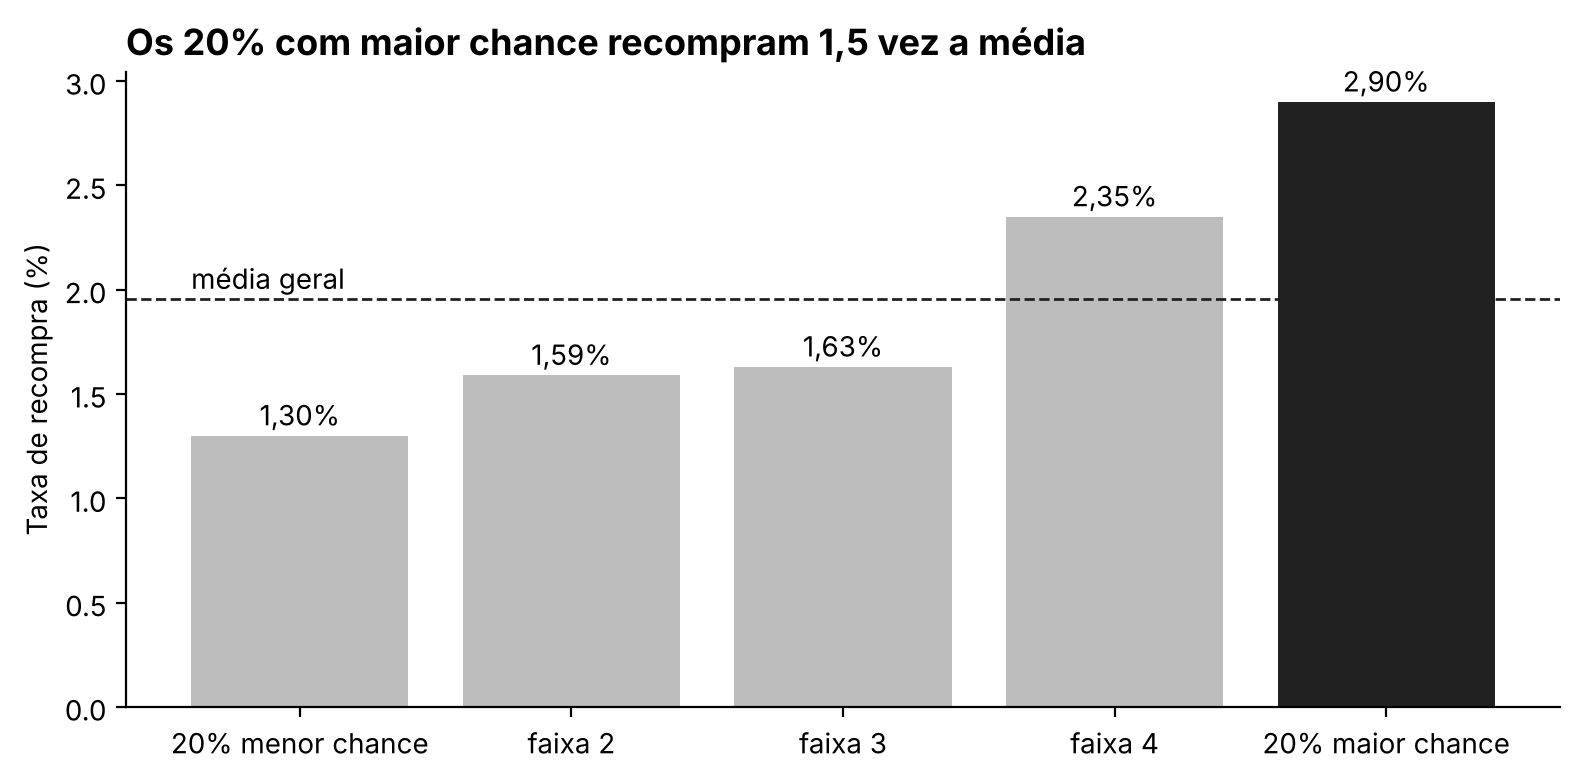

In [13]:
cores = [PRETO if faixa == "20% maior chance" else CINZA for faixa in por_faixa.index]

figura, eixo = plt.subplots(figsize=(8, 4))
eixo.bar(por_faixa.index, por_faixa["taxa_recompra_%"], color=cores)
eixo.axhline(taxa_geral, color=PRETO, linestyle="--", linewidth=1)
eixo.text(-0.4, taxa_geral + 0.05, "média geral", ha="left")
eixo.spines["top"].set_visible(False)
eixo.spines["right"].set_visible(False)
eixo.set_title("Os 20% com maior chance recompram 1,5 vez a média", loc="left", fontsize=13, fontweight="bold")
eixo.set_ylabel("Taxa de recompra (%)")
for posicao, valor in enumerate(por_faixa["taxa_recompra_%"]):
    eixo.text(posicao, valor + 0.05, f"{valor:.2f}%".replace(".", ","), ha="center")
plt.tight_layout()
plt.savefig(PASTA_IMAGENS + "09_recompra_por_faixa.png", dpi=150)
plt.show()

**Leitura:** o modelo ordena os clientes na direção certa, mas com pouca força.

- A faixa de maior chance recompra 2,90%. A de menor chance, 1,30%. É 2,2 vezes mais.
- Se o CRM só pudesse falar com 20% da base, o modelo entregaria 29,6% dos clientes que recompram. No sorteio, seriam 20%.

É um ganho real, mas pequeno. A taxa da melhor faixa ainda é de menos de 3 em cada 100.

## 6. O que o modelo aprendeu

A regressão logística dá um peso para cada pista. Peso positivo empurra a chance para cima. Peso negativo empurra para baixo.

In [14]:
nomes = melhor.named_steps["preparacao"].get_feature_names_out()
pesos = pd.Series(melhor.named_steps["modelo"].coef_[0], index=nomes)
pesos.index = pesos.index.str.replace("numeros__", "").str.replace("textos__", "")

print("Pistas que mais aumentam a chance:")
print(pesos.sort_values(ascending=False).head(6).round(2).to_string())
print()
print("Pistas que mais diminuem a chance:")
print(pesos.sort_values().head(6).round(2).to_string())

Pistas que mais aumentam a chance:
categoria_esporte_lazer       0.38
estado_ES                     0.35
categoria_cama_mesa_banho     0.35
categoria_moveis_decoracao    0.24
forma_pagamento_voucher       0.22
forma_pagamento_debit_card    0.21

Pistas que mais diminuem a chance:
categoria_cool_stuff              -0.73
estado_SC                         -0.27
forma_pagamento_credit_card       -0.26
categoria_automotivo              -0.22
estado_BA                         -0.22
categoria_utilidades_domesticas   -0.18


**Leitura:** as categorias de casa e esporte (esporte e lazer, cama, mesa e banho, móveis e decoração) aparecem ligadas a mais recompra. Faz sentido de negócio: são compras que puxam outras. Pagamento com voucher também aparece do lado positivo.

**Cuidado com esta leitura.** O modelo é fraco, então os pesos são pistas e não conclusões. Os pesos de estados como ES e SC podem ser só ruído. E peso mostra associação, não causa.

## 7. Conclusões

| Pergunta | Resposta |
|---|---|
| Dá para prever a recompra com os dados da primeira compra? | Pouco. AUC de 0,585 no teste e 0,572 na validação cruzada |
| O modelo serve para alguma coisa? | Os 20% com maior chance recompram 1,5 vez a média e concentram 29,6% dos recompradores |
| Qual foi o achado mais útil? | A recompra em outro dia é de 2,1%, não 3,0%. Parte das "recompras" era carrinho dividido |

### O que eu faria com isso

1. **Não usar este modelo sozinho para decidir investimento.** O ganho sobre o sorteio é pequeno.
2. **Usar a segmentação RFM da Parte 2 como base das réguas** e testar com grupo de controle.
3. **Buscar dados de comportamento.** A base só tem o pedido. Faltam os sinais que o CRM conhece bem: abertura de e-mail, clique, visita ao site, item no carrinho. É onde eu apostaria para melhorar o modelo.

### Limites da análise

- São só 1.080 clientes que recompraram na base do modelo. Com tão poucos casos, o modelo tem pouco de onde aprender.
- Usei a nota e o prazo de entrega do primeiro pedido como pistas. Alguns clientes recompraram antes de receber ou avaliar. Em um sistema real, eu fixaria o momento da previsão, por exemplo 30 dias depois da primeira compra.
- A janela de 180 dias é uma escolha. Outra janela daria outra taxa.